In [2]:
# Biblioteca para operações numéricas
import numpy as np

# Para visualização
import matplotlib.pyplot as plt

# Para redes neurais
import tensorflow as tf

# Interface de alto nível para construir redes neurais
from tensorflow import keras

# Importando as camadas da rede
from tensorflow.keras.layers import Conv2D, Input, MaxPooling2D, Flatten, Dense, Dropout

# Funções utilitárias para trabalhar com imagens
from tensorflow.keras.utils import load_img, img_to_array

# Carregar a base de dados CIFAR-10

In [3]:
# Carregar base CIFAR-10
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

# Normalizar os valores para um intervalo [0,1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# y vem como coluna
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

print("Formato de X_train:", X_train.shape)
print("Formato de X_test:", X_test.shape)
print("Formato de y_train:", y_train.shape)
print("Formato de y_test:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1247s 7us/step
Formato de X_train: (50000, 32, 32, 3)
Formato de X_test: (10000, 32, 32, 3)
Formato de y_train: (50000,)
Formato de y_test: (10000,)


Text(0.5, 0.98, 'Exemplos da base CIFAR-10')

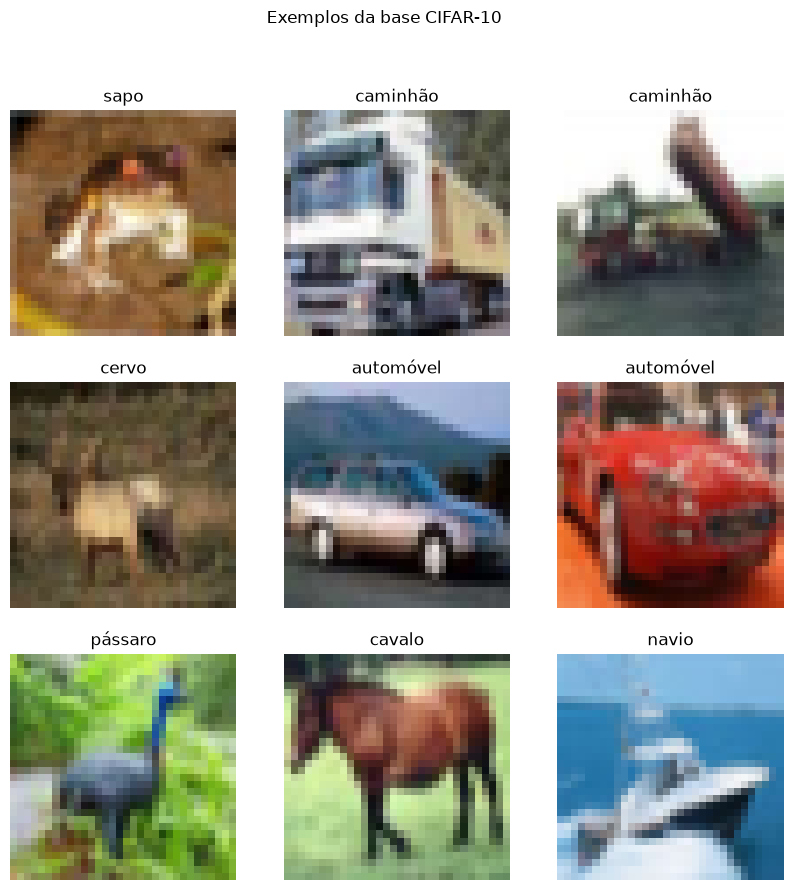

In [4]:
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.suptitle("Exemplos da base CIFAR-10")

# Criação do Modelo CNN

In [5]:
model = keras.Sequential()

# Camada de Entrada
model.add(Input(shape=(32, 32, 3)))

# Bloco 1
model.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu')) # Adiciona uma camada convolucional com 16 filtros
model.add(MaxPooling2D(pool_size=(2, 2))) # Adiciona uma camada de pooling para reduzir a dimensionalidade

# Bloco 2
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Bloco 3
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# kernel_size normalmente fica 3x3, 5x5, ou no máximo 7x7 (muito custoso). Pooling normalmente é 2x2.

# Transição CNN => Dense (Totalmente conectada)
model.add(Flatten()) # Achata a saída da CNN para uma dimensão
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Resumo da arquitetura do modelo
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,682 (158.91 KB)

 Trainable params: 40,682 (158.91 KB)

 Non-trainable params: 0 (0.00 B)

# Treinar a Rede

In [6]:
# Callbacks: ajudam a treinar de forma mais eficiente
# - EarlyStopping: interrompe o treino quando a val_loss para de melhorar por 5 épocas
#   e restaura os pesos da melhor época (evita overfitting)
# - ReduceLROnPlateau: reduz a taxa de aprendizado pela metade quando a val_loss estagna por 2 épocas
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5
    )
]

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks
)
# O número de época define quantas vezes o modelo vai passar pela base de dados
# Quanto maior o número de épocas, mais o modelo aprende, porém maior a chance de overfitting
# Com o EarlyStopping, o treino pode terminar antes das 50 épocas


Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.3850 - loss: 1.6752 - val_accuracy: 0.4837 - val_loss: 1.4406 - learning_rate: 0.0010
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.5181 - loss: 1.3384 - val_accuracy: 0.5145 - val_loss: 1.3590 - learning_rate: 0.0010
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.5740 - loss: 1.1997 - val_accuracy: 0.5771 - val_loss: 1.1805 - learning_rate: 0.0010
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6043 - loss: 1.1166 - val_accuracy: 0.6067 - val_loss: 1.1265 - learning_rate: 0.0010
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6293 - loss: 1.0498 - val_accuracy: 0.6154 - val_loss: 1.1122 - learning_rate: 0.0010
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.6479 - loss: 0.9986 - val_accuracy: 0.5962 - val_loss: 1.1510 - learning_rate: 0.0010
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6658 - l

# Plot da Acurácia e Loss

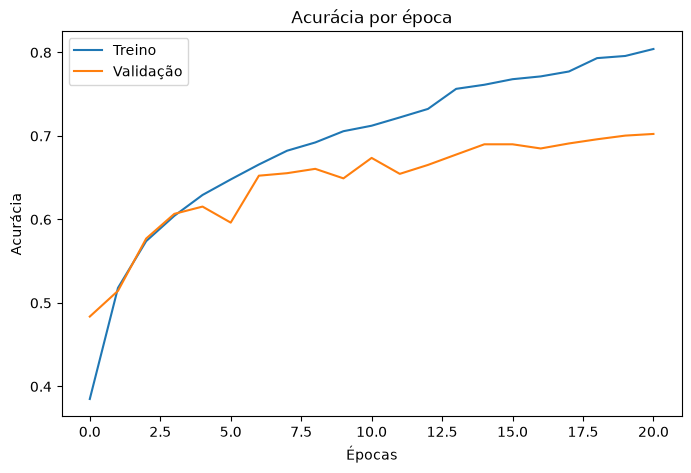

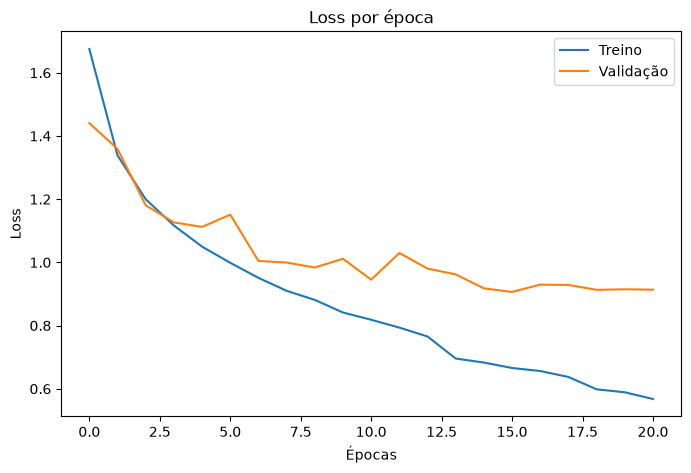

In [7]:
# Gráfico de Acurácia por Época
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Treino')
plt.plot(history.history['val_accuracy'], label='Validação')

plt.title("Acurácia por época")
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()
plt.show()

# Gráfico de Perda por Época
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Treino')
plt.plot(history.history['val_loss'], label='Validação')

plt.title("Loss por época")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Realizando Predições

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Acurácia no conjunto de teste: {test_acc:.4f}")
print(f"Loss no teste: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6896 - loss: 0.9279
Acurácia no conjunto de teste: 0.6896
Loss no teste: 0.9279


# Previsões em imagens do teste

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step


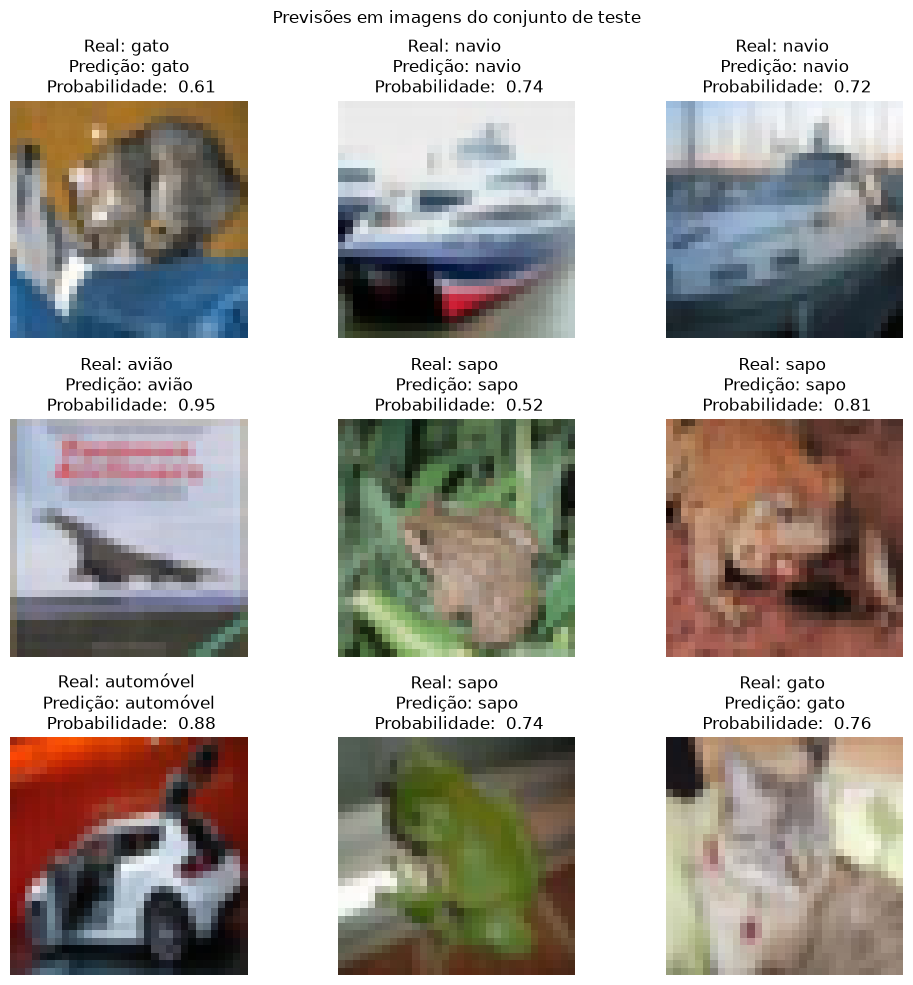

In [9]:
pred_probs = model.predict(X_test[:9])
pred_labels = np.argmax(pred_probs, axis=1)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    real = class_names[y_test[i]]
    pred = class_names[pred_labels[i]]
    plt.title(f"Real: {real} \n Predição: {pred} \n Probabilidade: {np.max(pred_probs[i]): .2f}")
    plt.axis('off')

plt.suptitle("Previsões em imagens do conjunto de teste")
plt.tight_layout()
plt.show()